<a href="https://colab.research.google.com/github/M9249/Function.py/blob/main/Copy_of_Kernel_Correlation_Convolution_DIP.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# Kernels, Correlation and Convolution in Digital Image Processing

**Design and Analysis of Algorithms / AI–ML Lab — Shobhit University**

This notebook builds every idea twice:

1. **Mathematically** — the definition, the formula, and a small worked example by hand.
2. **Visually** — a program that applies the idea to a tiny matrix and then to **your own image**.

**How to use:** Run the cells from top to bottom (`Runtime → Run all` or `Shift + Enter` one cell at a time). In Section 1 you will be asked to upload an image. If you skip the upload, a sample image is used.

| Section | Concept |
|---|---|
| 1 | Loading your image; an image is a matrix |
| 2 | What is a kernel? |
| 3 | Correlation |
| 4 | Convolution (and why the 180° rotation) |
| 5 | Correlation vs convolution — when are they equal? |
| 6 | Padding and output size |
| 7 | Step-by-step sliding animation |
| 8 | Smoothing kernels: box (average), weighted average, Gaussian |
| 9 | Noise removal, and the median filter (a non-linear contrast) |
| 10 | Sharpening kernels: Laplacian, unsharp masking, high-boost |
| 11 | First-derivative kernels: Prewitt and Sobel |
| 12 | Properties of kernels (sum of weights, separability) |
| 13 | Gallery of all kernels on your image |
| 14 | Interactive kernel playground |
| 15 | Summary and exercises |

## 0. Setup

We use only standard libraries: **NumPy** for the maths, **Matplotlib** for pictures, **OpenCV / SciPy** only to *check* that our own code gives the same answers as professional libraries.

In [ ]:
import numpy as np
import matplotlib.pyplot as plt
import matplotlib.patches as patches
import cv2
from scipy import ndimage, signal

plt.rcParams['figure.dpi'] = 100
plt.rcParams['axes.titlesize'] = 12
np.set_printoptions(precision=3, suppress=True, linewidth=120)

def show(images, titles, cmap='gray', cols=None, size=4, scale=None):
    # Display several images side by side.
    # scale = None  -> fixed range 0..255 (normal images)
    # scale = 'auto' -> stretch each image to its own min..max (for results with negative values)
    n = len(images)
    cols = cols or n
    rows = int(np.ceil(n / cols))
    fig, axes = plt.subplots(rows, cols, figsize=(size * cols, size * rows))
    axes = np.atleast_1d(axes).ravel()
    for ax, im, t in zip(axes, images, titles):
        if im.ndim == 3:
            ax.imshow(np.clip(im, 0, 255).astype(np.uint8))
        elif scale == 'auto':
            ax.imshow(im, cmap=cmap)
        else:
            ax.imshow(np.clip(im, 0, 255), cmap=cmap, vmin=0, vmax=255)
        ax.set_title(t)
        ax.axis('off')
    for ax in axes[n:]:
        ax.axis('off')
    plt.tight_layout()
    plt.show()

def show_matrix(ax, A, title='', fmt='{:g}', cmap='Greys_r', highlight=None, hl_color='orange', vmin=None, vmax=None):
    # Draw a small matrix as coloured squares with its numbers written inside.
    A = np.asarray(A, dtype=float)
    ax.imshow(A, cmap=cmap, vmin=vmin, vmax=vmax)
    lo, hi = (A.min() if vmin is None else vmin), (A.max() if vmax is None else vmax)
    mid = (lo + hi) / 2
    for i in range(A.shape[0]):
        for j in range(A.shape[1]):
            ax.text(j, i, fmt.format(A[i, j]), ha='center', va='center', fontsize=11,
                    color='black' if A[i, j] > mid else 'white', fontweight='bold')
    if highlight is not None:   # (row, col, height, width)
        r, c, h, w = highlight
        ax.add_patch(patches.Rectangle((c - .5, r - .5), w, h, fill=False, ec=hl_color, lw=3))
    ax.set_xticks(range(A.shape[1])); ax.set_yticks(range(A.shape[0]))
    ax.set_title(title)

print('Setup complete.')

Setup complete.


## 1. Load your image — and see that an image is a matrix

**Question: What is a digital image, mathematically?**

**Answer:** A grayscale digital image is a function $f(x, y)$ sampled on a grid. It is stored as an $M \times N$ matrix, where $x$ is the **row**, $y$ is the **column**, and each entry is the brightness (intensity), usually an integer from $0$ (black) to $255$ (white).

$$
f = \begin{bmatrix}
f(0,0) & f(0,1) & \cdots & f(0,N-1)\\
f(1,0) & f(1,1) & \cdots & f(1,N-1)\\
\vdots & \vdots & \ddots & \vdots\\
f(M-1,0) & f(M-1,1) & \cdots & f(M-1,N-1)
\end{bmatrix}
$$

A colour image is three such matrices (Red, Green, Blue). For clarity, most of this notebook works on the grayscale version, and Section 13 shows a colour example.

Run the next cell and click **Choose Files** to upload any `.jpg` or `.png` image.

Upload an image (jpg / png). Press Cancel to use a sample image.


Saving WhatsApp Image 2026-09-25 at 9.52.28 AMq.jpeg to WhatsApp Image 2026-09-25 at 9.52.28 AMq.jpeg
Loaded: WhatsApp Image 2026-09-25 at 9.52.28 AMq.jpeg
Colour image shape (rows, cols, channels): (512, 384, 3)
Grayscale matrix shape (M, N): (512, 384)


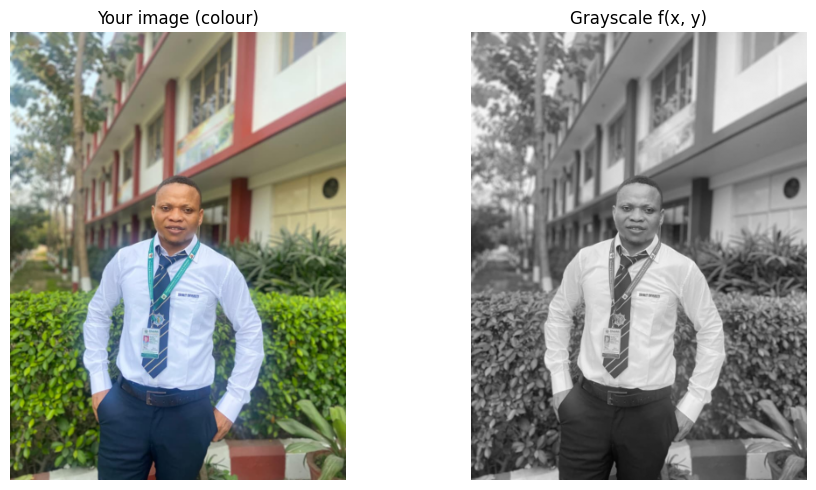

In [ ]:
def load_user_image(max_side=512):
    data = None
    try:
        from google.colab import files
        print('Upload an image (jpg / png). Press Cancel to use a sample image.')
        uploaded = files.upload()
        if uploaded:
            name = list(uploaded.keys())[0]
            data = np.frombuffer(uploaded[name], np.uint8)
            print('Loaded:', name)
    except Exception:
        print('Not running in Colab (or upload skipped).')

    if data is not None:
        bgr = cv2.imdecode(data, cv2.IMREAD_COLOR)
        rgb = cv2.cvtColor(bgr, cv2.COLOR_BGR2RGB)
    else:
        from skimage import data as skdata
        rgb = skdata.astronaut()
        print('Using the sample image (skimage astronaut).')

    # Resize large photos so that the from-scratch code runs quickly
    h, w = rgb.shape[:2]
    k = max_side / max(h, w)
    if k < 1:
        rgb = cv2.resize(rgb, (int(w * k), int(h * k)), interpolation=cv2.INTER_AREA)
    return rgb

img_color = load_user_image()
img = cv2.cvtColor(img_color, cv2.COLOR_RGB2GRAY).astype(float)   # f(x, y) as a float matrix
print('Colour image shape (rows, cols, channels):', img_color.shape)
print('Grayscale matrix shape (M, N):', img.shape)
show([img_color, img], ['Your image (colour)', 'Grayscale f(x, y)'], size=5)

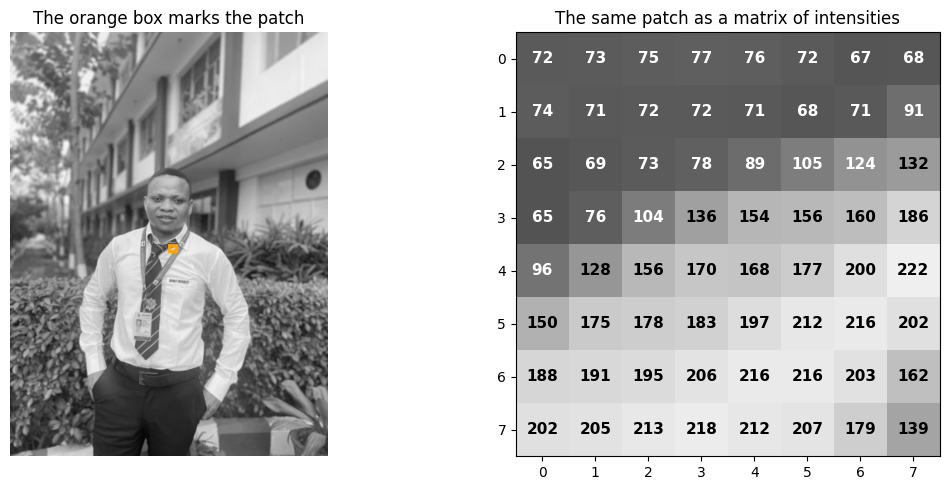

In [ ]:
# Zoom in: a small 8 x 8 patch really is just numbers.
r0, c0 = img.shape[0] // 2, img.shape[1] // 2
patch = img[r0:r0 + 8, c0:c0 + 8]

fig, ax = plt.subplots(1, 2, figsize=(12, 5))
ax[0].imshow(img, cmap='gray', vmin=0, vmax=255)
ax[0].add_patch(patches.Rectangle((c0, r0), 8, 8, fill=False, ec='orange', lw=2))
ax[0].set_title('The orange box marks the patch'); ax[0].axis('off')
show_matrix(ax[1], patch, 'The same patch as a matrix of intensities', fmt='{:.0f}', vmin=0, vmax=255)
plt.tight_layout(); plt.show()

## 2. What is a kernel?

**Question: What is a kernel (also called a mask, filter, or template)?**

**Answer:** A kernel is a small matrix of **weights**, usually of odd size $m \times n$ (for example $3 \times 3$ or $5 \times 5$), that we slide over the image. At every position, each weight multiplies the pixel under it and the products are added to give **one output pixel**.

We index the kernel from its **centre**, so that the centre weight is $w(0,0)$:

$$
m = 2a + 1,\qquad n = 2b + 1,\qquad s \in \{-a,\dots,a\},\quad t \in \{-b,\dots,b\}
$$

For a $3 \times 3$ kernel, $a = b = 1$:

$$
w = \begin{bmatrix}
w(-1,-1) & w(-1,0) & w(-1,1)\\
w(0,-1) & w(0,0) & w(0,1)\\
w(1,-1) & w(1,0) & w(1,1)
\end{bmatrix}
$$

**In Python**, arrays start at index 0, so $w(s,t)$ is stored at `w[s + a, t + b]`. This one line is the bridge between the textbook formula and the code.

**Why odd sizes?** An odd-sized kernel has a single centre pixel, so the output pixel lines up exactly with the input pixel under the centre.

**What the weights decide:** the *values* of the weights decide what the filter does — blur, sharpen, or detect edges. Sections 8–11 build each type.

w(s, t) is stored at w[s + a, t + b]:
w(-1,-1) = 1   w(-1,+0) = 2   w(-1,+1) = 3
w(+0,-1) = 4   w(+0,+0) = 5   w(+0,+1) = 6
w(+1,-1) = 7   w(+1,+0) = 8   w(+1,+1) = 9


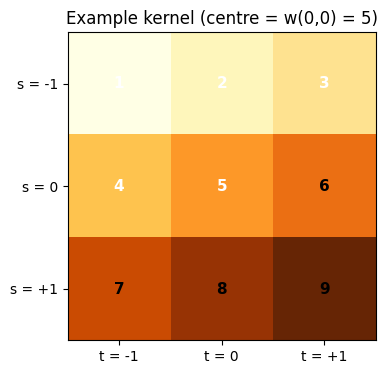

In [ ]:
w_example = np.array([[1, 2, 3],
                      [4, 5, 6],
                      [7, 8, 9]], dtype=float)
a = b = 1
print('w(s, t) is stored at w[s + a, t + b]:')
for s in range(-a, a + 1):
    print('   '.join(f'w({s:+d},{t:+d}) = {w_example[s + a, t + b]:g}' for t in range(-b, b + 1)))

fig, ax = plt.subplots(figsize=(4, 4))
show_matrix(ax, w_example, 'Example kernel (centre = w(0,0) = 5)', cmap='YlOrBr')
ax.set_xticklabels(['t = -1', 't = 0', 't = +1']); ax.set_yticklabels(['s = -1', 's = 0', 's = +1'])
plt.show()

## 3. Correlation

**Question: What is spatial correlation?**

**Answer:** Place the kernel's centre on pixel $(x, y)$, multiply each weight by the pixel directly beneath it, and add the products. Repeat for every pixel. The kernel is used **exactly as written**.

$$
g(x, y) \;=\; (w \star f)(x, y) \;=\; \sum_{s=-a}^{a}\;\sum_{t=-b}^{b} w(s, t)\, f(x + s,\; y + t)
$$

Note the **plus signs**: weight $w(s,t)$ meets pixel $f(x+s, y+t)$, so the top-left weight $w(-1,-1)$ meets the top-left neighbour $f(x-1, y-1)$.

### Worked example by hand

Take this $5 \times 5$ image and the kernel from Section 2. Compute $g(2,2)$, the centre pixel.

$$
f = \begin{bmatrix}
1 & 2 & 0 & 3 & 1\\
0 & 1 & 4 & 1 & 2\\
2 & 3 & 1 & 0 & 1\\
1 & 0 & 2 & 2 & 0\\
3 & 1 & 1 & 0 & 2
\end{bmatrix},
\qquad
w = \begin{bmatrix} 1 & 2 & 3\\ 4 & 5 & 6\\ 7 & 8 & 9 \end{bmatrix}
$$

The $3 \times 3$ neighbourhood of $f(2,2)$ is $\begin{bmatrix} 1 & 4 & 1\\ 3 & 1 & 0\\ 0 & 2 & 2\end{bmatrix}$. Multiply position by position and add:

$$
g(2,2) = 1\cdot1 + 2\cdot4 + 3\cdot1 + 4\cdot3 + 5\cdot1 + 6\cdot0 + 7\cdot0 + 8\cdot2 + 9\cdot2 = 63
$$

The next cell writes the formula literally as four loops, so that every symbol in the equation has a matching line of code.

In [ ]:
def correlate_formula(f, w):
    # Correlation written EXACTLY as the formula, with zero padding outside the image.
    #   g(x, y) = sum_s sum_t  w(s, t) * f(x + s, y + t)
    M, N = f.shape
    m, n = w.shape
    a, b = m // 2, n // 2
    g = np.zeros((M, N))
    for x in range(M):
        for y in range(N):
            total = 0.0
            for s in range(-a, a + 1):
                for t in range(-b, b + 1):
                    xi, yi = x + s, y + t                  # <-- the PLUS signs
                    if 0 <= xi < M and 0 <= yi < N:        # outside the image counts as 0
                        total += w[s + a, t + b] * f[xi, yi]
            g[x, y] = total
    return g

f_small = np.array([[1, 2, 0, 3, 1],
                    [0, 1, 4, 1, 2],
                    [2, 3, 1, 0, 1],
                    [1, 0, 2, 2, 0],
                    [3, 1, 1, 0, 2]], dtype=float)

g_corr = correlate_formula(f_small, w_example)
print('g(2, 2) by correlation =', g_corr[2, 2], '  (hand calculation: 63)')
print('\nFull correlation output (zero padding):\n', g_corr)

g(2, 2) by correlation = 63.0   (hand calculation: 63)

Full correlation output (zero padding):
 [[26. 58. 74. 75. 40.]
 [57. 81. 70. 58. 27.]
 [39. 68. 63. 52. 24.]
 [51. 65. 42. 47. 26.]
 [23. 30. 19. 22. 12.]]


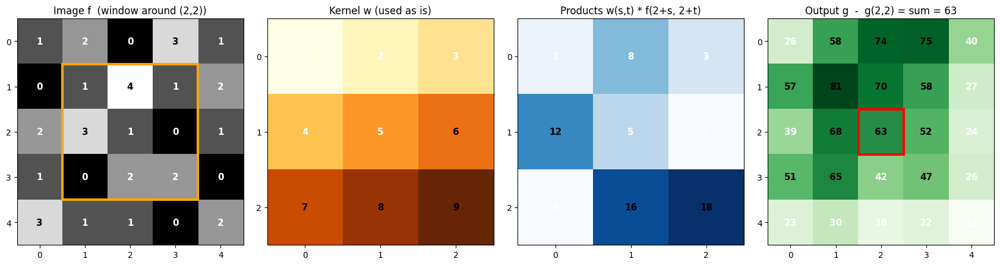

In [ ]:
# Visual: the neighbourhood, the kernel, and their element-wise products for g(2, 2)
region = f_small[1:4, 1:4]
products = region * w_example

fig, ax = plt.subplots(1, 4, figsize=(17, 4.2))
show_matrix(ax[0], f_small, 'Image f  (window around (2,2))', highlight=(1, 1, 3, 3))
show_matrix(ax[1], w_example, 'Kernel w (used as is)', cmap='YlOrBr')
show_matrix(ax[2], products, 'Products w(s,t) * f(2+s, 2+t)', cmap='Blues')
show_matrix(ax[3], g_corr, 'Output g  -  g(2,2) = sum = 63', fmt='{:.0f}', cmap='Greens', highlight=(2, 2, 1, 1), hl_color='red')
plt.tight_layout(); plt.show()

## 4. Convolution

**Question: What is spatial convolution, and how is it different from correlation?**

**Answer:** Convolution is correlation with the kernel **rotated by 180°** (flipped top-to-bottom *and* left-to-right). In the formula, the plus signs become **minus signs**:

$$
g(x, y) \;=\; (w * f)(x, y) \;=\; \sum_{s=-a}^{a}\;\sum_{t=-b}^{b} w(s, t)\, f(x - s,\; y - t)
$$

Now weight $w(s,t)$ meets pixel $f(x-s, y-t)$: the **top-left** weight $w(-1,-1)$ meets the **bottom-right** neighbour $f(x+1, y+1)$. That is exactly what happens if you rotate the kernel by 180° and then correlate.

### Proof that the minus signs equal a 180° rotation

Let $\tilde{w}(s, t) = w(-s, -t)$ be the rotated kernel. Substitute $s' = -s,\; t' = -t$ (the sums still run over the same symmetric range $-a \dots a$):

$$
\sum_{s}\sum_{t} w(s,t)\, f(x-s,\, y-t)
= \sum_{s'}\sum_{t'} w(-s',-t')\, f(x+s',\, y+t')
= \sum_{s'}\sum_{t'} \tilde{w}(s',t')\, f(x+s',\, y+t')
$$

The right-hand side is the **correlation** of $f$ with $\tilde{w}$. So:

$$
\boxed{\; w * f \;=\; \operatorname{rot}_{180}(w) \star f \;}
$$

### Worked example

$\operatorname{rot}_{180}(w) = \begin{bmatrix} 9 & 8 & 7\\ 6 & 5 & 4\\ 3 & 2 & 1\end{bmatrix}$. Using the same neighbourhood as before:

$$
g(2,2) = 9\cdot1 + 8\cdot4 + 7\cdot1 + 6\cdot3 + 5\cdot1 + 4\cdot0 + 3\cdot0 + 2\cdot2 + 1\cdot2 = 77
$$

Correlation gave $63$, convolution gives $77$ — the same image and kernel, two different answers, because this kernel changes when rotated.

In [ ]:
def convolve_formula(f, w):
    # Convolution written EXACTLY as the formula (minus signs), zero padding.
    #   g(x, y) = sum_s sum_t  w(s, t) * f(x - s, y - t)
    M, N = f.shape
    m, n = w.shape
    a, b = m // 2, n // 2
    g = np.zeros((M, N))
    for x in range(M):
        for y in range(N):
            total = 0.0
            for s in range(-a, a + 1):
                for t in range(-b, b + 1):
                    xi, yi = x - s, y - t                  # <-- the MINUS signs
                    if 0 <= xi < M and 0 <= yi < N:
                        total += w[s + a, t + b] * f[xi, yi]
            g[x, y] = total
    return g

w_rot = np.rot90(w_example, 2)          # rotate by 180 degrees
g_conv = convolve_formula(f_small, w_example)
g_conv_via_rot = correlate_formula(f_small, w_rot)

print('Rotated kernel rot180(w):\n', w_rot)
print('\ng(2, 2) by convolution =', g_conv[2, 2], '  (hand calculation: 77)')
print('Minus-sign formula == correlation with rotated kernel?', np.allclose(g_conv, g_conv_via_rot))

Rotated kernel rot180(w):
 [[9. 8. 7.]
 [6. 5. 4.]
 [3. 2. 1.]]

g(2, 2) by convolution = 77.0   (hand calculation: 77)
Minus-sign formula == correlation with rotated kernel? True


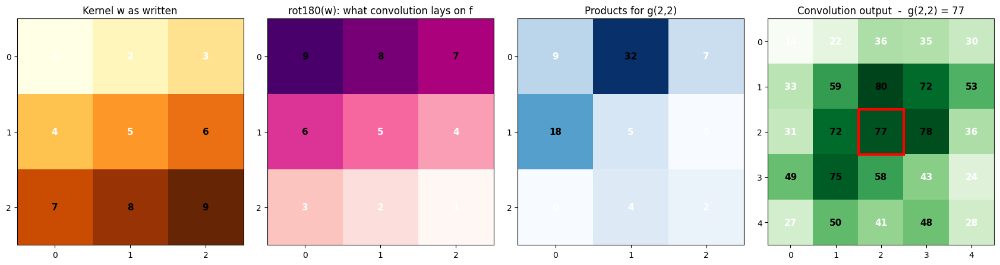

In [ ]:
fig, ax = plt.subplots(1, 4, figsize=(17, 4.2))
show_matrix(ax[0], w_example, 'Kernel w as written', cmap='YlOrBr')
show_matrix(ax[1], w_rot, 'rot180(w): what convolution lays on f', cmap='RdPu')
show_matrix(ax[2], f_small[1:4, 1:4] * w_rot, 'Products for g(2,2)', cmap='Blues')
show_matrix(ax[3], g_conv, 'Convolution output  -  g(2,2) = 77', fmt='{:.0f}', cmap='Greens', highlight=(2, 2, 1, 1), hl_color='red')
plt.tight_layout(); plt.show()

### Why does convolution use the flip? The impulse experiment

**Question: Why would anyone define convolution with an awkward rotation?**

**Answer:** Because with the rotation, convolving a kernel with a **unit impulse** (a single pixel of value 1) gives back **the kernel itself**, the right way round. Correlation gives the kernel rotated by 180°. This "impulse response" property is what makes convolution the natural operation in signal processing, and it makes convolution **commutative** and **associative** (Section 12).

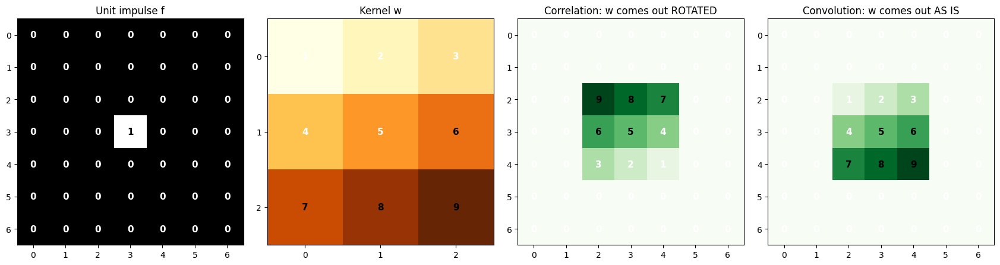

In [ ]:
impulse = np.zeros((7, 7)); impulse[3, 3] = 1

fig, ax = plt.subplots(1, 4, figsize=(17, 4.2))
show_matrix(ax[0], impulse, 'Unit impulse f')
show_matrix(ax[1], w_example, 'Kernel w', cmap='YlOrBr')
show_matrix(ax[2], correlate_formula(impulse, w_example), 'Correlation: w comes out ROTATED', cmap='Greens')
show_matrix(ax[3], convolve_formula(impulse, w_example), 'Convolution: w comes out AS IS', cmap='Greens')
plt.tight_layout(); plt.show()

## 5. Correlation vs convolution — when are they equal?

**Question: Do we always have to worry about the flip?**

**Answer:** Only for kernels that change under a 180° rotation.

| Kernel type | Condition | Result |
|---|---|---|
| Symmetric | $w(-s,-t) = w(s,t)$ | $w * f = w \star f$ (identical) |
| Anti-symmetric | $w(-s,-t) = -w(s,t)$ | $w * f = -(w \star f)$ (sign flips) |
| General | neither | different outputs |

Smoothing kernels (box, Gaussian) and the Laplacian are symmetric, which is why many textbooks say "convolution" while their code actually performs correlation. Sobel and Prewitt are anti-symmetric.

**Important practical fact:** `cv2.filter2D` and `scipy.ndimage.correlate` perform **correlation**. `scipy.signal.convolve2d` and `scipy.ndimage.convolve` perform true **convolution**. The next cell checks our formula-based code against these libraries.

In [ ]:
def correlate(f, w, padding='zero'):
    # Fast correlation: same maths as correlate_formula, but the two pixel loops are
    # replaced by shifting the whole padded image (one shift per kernel weight).
    m, n = w.shape
    a, b = m // 2, n // 2
    mode = {'zero': 'constant', 'replicate': 'edge', 'reflect': 'reflect'}[padding]
    fp = np.pad(f.astype(float), ((a, a), (b, b)), mode=mode)
    M, N = f.shape
    g = np.zeros((M, N))
    for s in range(-a, a + 1):
        for t in range(-b, b + 1):
            g += w[s + a, t + b] * fp[a + s: a + s + M, b + t: b + t + N]   # f(x+s, y+t) for all x, y
    return g

def convolve(f, w, padding='zero'):
    # Convolution = correlation with the kernel rotated by 180 degrees.
    return correlate(f, np.rot90(w, 2), padding)

rng = np.random.default_rng(0)
F = rng.integers(0, 10, (6, 6)).astype(float)

print('Our fast correlate == formula version:          ', np.allclose(correlate(F, w_example), correlate_formula(F, w_example)))
print('Our correlate == scipy.ndimage.correlate:        ', np.allclose(correlate(F, w_example), ndimage.correlate(F, w_example, mode='constant')))
print('Our correlate == cv2.filter2D (zero border):     ', np.allclose(correlate(F, w_example), cv2.filter2D(F, -1, w_example, borderType=cv2.BORDER_CONSTANT)))
print('Our convolve  == scipy.signal.convolve2d(same):  ', np.allclose(convolve(F, w_example), signal.convolve2d(F, w_example, mode='same', boundary='fill')))
print('cv2.filter2D == TRUE convolution for this kernel?', np.allclose(cv2.filter2D(F, -1, w_example, borderType=cv2.BORDER_CONSTANT), convolve(F, w_example)))

Our fast correlate == formula version:           True
Our correlate == scipy.ndimage.correlate:         True
Our correlate == cv2.filter2D (zero border):      True
Our convolve  == scipy.signal.convolve2d(same):   True
cv2.filter2D == TRUE convolution for this kernel? False


Box (symmetric)            | same output: True  | conv == -corr: False
Sobel x (anti-symmetric)   | same output: False | conv == -corr: True
Numbered 1-9 (general)     | same output: False | conv == -corr: False


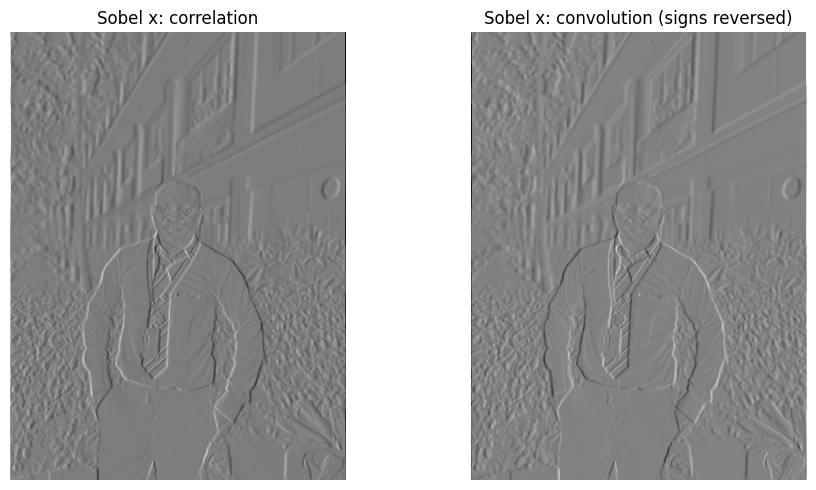

In [ ]:
kernels_test = {
    'Box (symmetric)':          np.ones((3, 3)) / 9,
    'Sobel x (anti-symmetric)': np.array([[-1, 0, 1], [-2, 0, 2], [-1, 0, 1]], float),
    'Numbered 1-9 (general)':   w_example,
}
for name, k in kernels_test.items():
    c, v = correlate(img, k), convolve(img, k)
    print(f'{name:26s} | same output: {np.allclose(c, v)!s:5s} | conv == -corr: {np.allclose(v, -c)}')

k = kernels_test['Sobel x (anti-symmetric)']
show([correlate(img, k), convolve(img, k)],
     ['Sobel x: correlation', 'Sobel x: convolution (signs reversed)'], scale='auto', size=5)

## 6. Padding and output size

**Question: What happens at the border, where the kernel hangs off the image?**

**Answer:** Either we **do not let the kernel hang off** (the output shrinks), or we **pad** the image with extra rows and columns.

For an $M \times N$ image and an $m \times n$ kernel:

- **No padding ("valid")**: output size is $(M - m + 1) \times (N - n + 1)$.
- **Padding ("same")**: add $a = \frac{m-1}{2}$ rows on top and bottom and $b = \frac{n-1}{2}$ columns on each side; output size stays $M \times N$.

Common padding choices:

| Padding | Value used outside the image | Effect at borders |
|---|---|---|
| Zero | $0$ | dark frame after blurring |
| Replicate | copy of the nearest edge pixel | usually looks natural |
| Reflect / mirror | mirror image of pixels near the edge | usually looks natural |

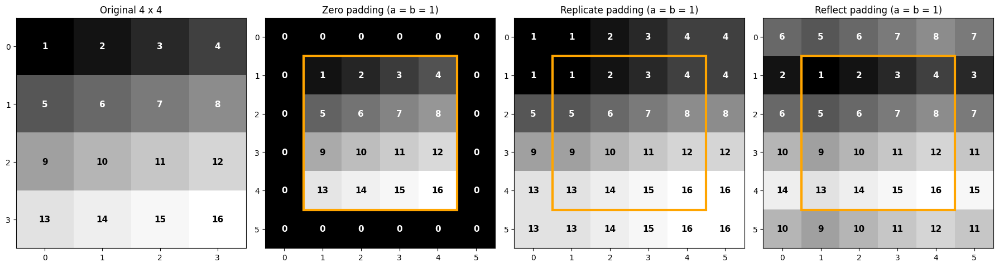

3x3 kernel on a 512x384 image: valid output = 510x382, padded output = 512x384
5x5 kernel on a 512x384 image: valid output = 508x380, padded output = 512x384
15x15 kernel on a 512x384 image: valid output = 498x370, padded output = 512x384


In [ ]:
A = np.arange(1, 17, dtype=float).reshape(4, 4)
fig, ax = plt.subplots(1, 4, figsize=(18, 4.5))
show_matrix(ax[0], A, 'Original 4 x 4')
for k, (name, mode) in enumerate([('Zero', 'constant'), ('Replicate', 'edge'), ('Reflect', 'reflect')], start=1):
    show_matrix(ax[k], np.pad(A, 1, mode=mode), f'{name} padding (a = b = 1)', highlight=(1, 1, 4, 4))
plt.tight_layout(); plt.show()

M, N = img.shape
for m in (3, 5, 15):
    print(f'{m}x{m} kernel on a {M}x{N} image: valid output = {M - m + 1}x{N - m + 1}, padded output = {M}x{N}')

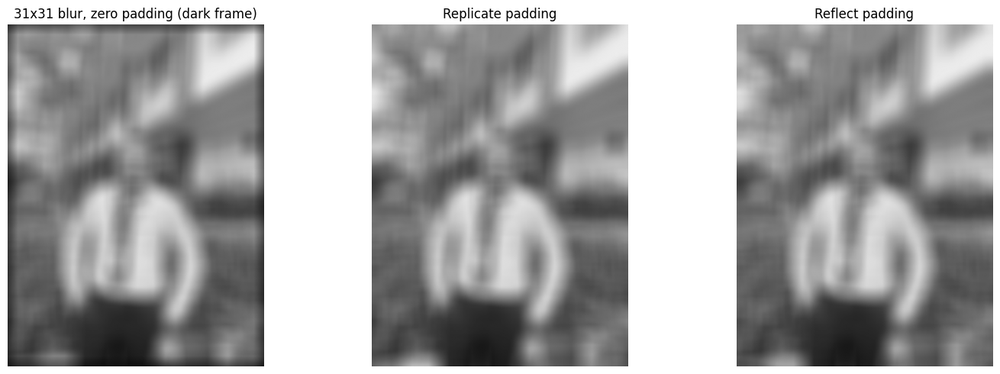

In [ ]:
# Effect of the padding choice on a strong blur (look at the borders)
big_box = np.ones((31, 31)) / 31**2
show([correlate(img, big_box, 'zero'), correlate(img, big_box, 'replicate'), correlate(img, big_box, 'reflect')],
     ['31x31 blur, zero padding (dark frame)', 'Replicate padding', 'Reflect padding'], size=5)

## 7. Step-by-step: watch the kernel slide

**Question: What exactly happens at each position?**

**Answer:** At each output position $(x, y)$: (1) place the kernel (rotated if convolving) centred on $(x, y)$; (2) multiply each weight by the pixel under it; (3) add the 9 products; (4) write the sum into $g(x, y)$.

Use the sliders below to move the kernel and switch between correlation and convolution. Each frame prints the full sum, term by term.

In [ ]:
def explain_step(f, w, x, y, mode='correlation'):
    a = w.shape[0] // 2
    w_used = w if mode == 'correlation' else np.rot90(w, 2)
    fp = np.pad(f, a)                                     # zero padding
    region = fp[x:x + 2 * a + 1, y:y + 2 * a + 1]          # neighbourhood of (x, y)
    prods = w_used * region
    full = correlate(f, w_used)
    so_far = np.full(f.shape, np.nan)
    flat = x * f.shape[1] + y
    so_far.flat[:flat + 1] = full.flat[:flat + 1]          # fill in raster order up to (x, y)

    terms = ' + '.join(f'{wv:g}*{fv:g}' for wv, fv in zip(w_used.ravel(), region.ravel()))
    print(f'{mode}:  g({x},{y}) = {terms} = {prods.sum():g}')

    fig, ax = plt.subplots(1, 4, figsize=(18, 4.4))
    show_matrix(ax[0], fp, f'Padded f  (window centred on ({x},{y}))', highlight=(x, y, 2 * a + 1, 2 * a + 1))
    show_matrix(ax[1], w_used, 'Kernel laid on f' + ('' if mode == 'correlation' else '  (rotated 180)'),
                cmap='YlOrBr' if mode == 'correlation' else 'RdPu')
    show_matrix(ax[2], prods, 'Element-wise products', cmap='Blues')
    ax[3].imshow(np.nan_to_num(so_far, nan=0), cmap='Greens')
    for i in range(f.shape[0]):
        for j in range(f.shape[1]):
            if not np.isnan(so_far[i, j]):
                ax[3].text(j, i, f'{so_far[i, j]:g}', ha='center', va='center', fontsize=10, fontweight='bold')
    ax[3].add_patch(patches.Rectangle((y - .5, x - .5), 1, 1, fill=False, ec='red', lw=3))
    ax[3].set_title(f'Output g so far  (g({x},{y}) = {prods.sum():g})')
    ax[3].set_xticks(range(f.shape[1])); ax[3].set_yticks(range(f.shape[0]))
    plt.tight_layout(); plt.show()

try:
    import ipywidgets as widgets
    widgets.interact(lambda x, y, mode: explain_step(f_small, w_example, x, y, mode),
                     x=widgets.IntSlider(min=0, max=4, value=2, description='row x'),
                     y=widgets.IntSlider(min=0, max=4, value=2, description='col y'),
                     mode=widgets.ToggleButtons(options=['correlation', 'convolution']))
except ImportError:
    explain_step(f_small, w_example, 2, 2, 'correlation')
    explain_step(f_small, w_example, 2, 2, 'convolution')

interactive(children=(IntSlider(value=2, description='row x', max=4), IntSlider(value=2, description='col y', …

## 8. Smoothing kernels (low-pass filters)

**Question: What does a smoothing kernel do?**

**Answer:** It replaces each pixel by a **weighted average** of its neighbourhood. Sharp changes (noise, fine detail, edges) are averaged away, so the image becomes blurred and less noisy. All weights are positive and **sum to 1**, so the overall brightness does not change.

### 8.1 Box filter (simple average)

Every neighbour gets the same weight. For an $m \times m$ box:

$$
w(s,t) = \frac{1}{m^2},\qquad
w_{3\times3} = \frac{1}{9}\begin{bmatrix}1&1&1\\1&1&1\\1&1&1\end{bmatrix},\qquad
g(x,y) = \frac{1}{9}\sum_{s=-1}^{1}\sum_{t=-1}^{1} f(x+s, y+t)
$$

So $g(x,y)$ is literally the **arithmetic mean** of the 9 pixels. Bigger kernels average over more pixels and blur more.

### 8.2 Weighted average

Nearer pixels should matter more than far ones. A common $3 \times 3$ choice:

$$
w = \frac{1}{16}\begin{bmatrix}1&2&1\\2&4&2\\1&2&1\end{bmatrix}
$$

The centre has weight $\tfrac{4}{16}$, edge neighbours $\tfrac{2}{16}$, corners $\tfrac{1}{16}$; the sum is $\tfrac{16}{16} = 1$.

### 8.3 Gaussian kernel

The weights follow the 2-D Gaussian bell curve:

$$
G(s, t) = K\, e^{-\frac{s^2 + t^2}{2\sigma^2}},
\qquad K \text{ chosen so that } \sum_s \sum_t G(s,t) = 1
$$

$\sigma$ (sigma) controls the spread: larger $\sigma$ means more blur. A rule of thumb is a kernel size of about $6\sigma$ (rounded up to an odd number), because the Gaussian is almost zero beyond $3\sigma$ from the centre.

In [ ]:
def box_kernel(m):
    return np.ones((m, m)) / (m * m)

def weighted_avg_kernel():
    return np.array([[1, 2, 1], [2, 4, 2], [1, 2, 1]], float) / 16

def gaussian_kernel(size, sigma):
    a = size // 2
    s, t = np.mgrid[-a:a + 1, -a:a + 1]                    # s = rows, t = columns
    G = np.exp(-(s**2 + t**2) / (2 * sigma**2))
    return G / G.sum()                                     # normalise so the weights sum to 1

print('Box 3x3:\n', box_kernel(3), '  sum =', box_kernel(3).sum())
print('\nWeighted average:\n', weighted_avg_kernel(), '  sum =', weighted_avg_kernel().sum())
G5 = gaussian_kernel(5, 1.0)
print('\nGaussian 5x5, sigma = 1:\n', G5, '  sum =', round(G5.sum(), 6))

Box 3x3:
 [[0.111 0.111 0.111]
 [0.111 0.111 0.111]
 [0.111 0.111 0.111]]   sum = 1.0

Weighted average:
 [[0.062 0.125 0.062]
 [0.125 0.25  0.125]
 [0.062 0.125 0.062]]   sum = 1.0

Gaussian 5x5, sigma = 1:
 [[0.003 0.013 0.022 0.013 0.003]
 [0.013 0.06  0.098 0.06  0.013]
 [0.022 0.098 0.162 0.098 0.022]
 [0.013 0.06  0.098 0.06  0.013]
 [0.003 0.013 0.022 0.013 0.003]]   sum = 1.0


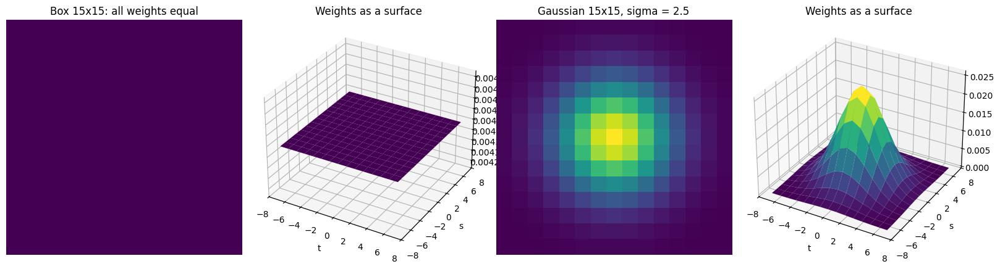

In [ ]:
# Look at the kernels themselves: flat box vs bell-shaped Gaussian
from mpl_toolkits.mplot3d import Axes3D  # noqa: F401
fig = plt.figure(figsize=(16, 4.5))
for k, (K, title) in enumerate([(box_kernel(15), 'Box 15x15: all weights equal'),
                                (gaussian_kernel(15, 2.5), 'Gaussian 15x15, sigma = 2.5')]):
    ax = fig.add_subplot(1, 4, 2 * k + 1)
    ax.imshow(K, cmap='viridis'); ax.set_title(title); ax.axis('off')
    ax = fig.add_subplot(1, 4, 2 * k + 2, projection='3d')
    a = K.shape[0] // 2
    S, T = np.mgrid[-a:a + 1, -a:a + 1]
    ax.plot_surface(T, S, K, cmap='viridis'); ax.set_title('Weights as a surface')
    ax.set_xlabel('t'); ax.set_ylabel('s')
plt.tight_layout(); plt.show()

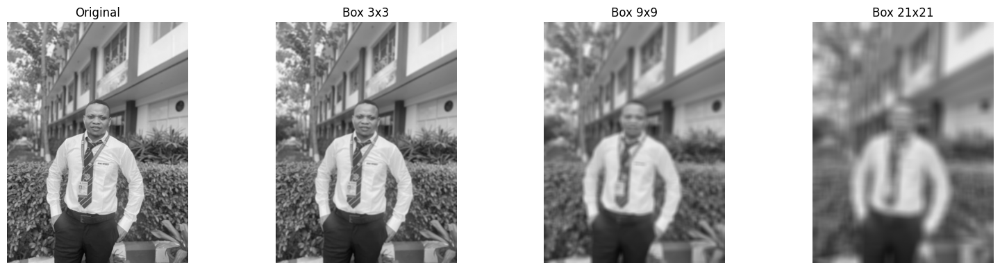

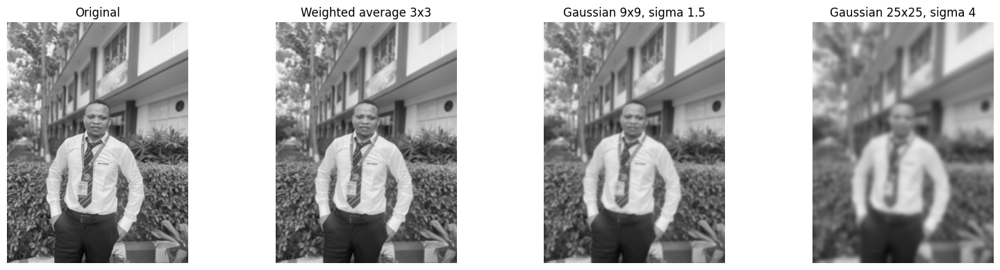

In [ ]:
# Apply to your image
show([img, correlate(img, box_kernel(3), 'reflect'), correlate(img, box_kernel(9), 'reflect'), correlate(img, box_kernel(21), 'reflect')],
     ['Original', 'Box 3x3', 'Box 9x9', 'Box 21x21'], cols=4)
show([img, correlate(img, weighted_avg_kernel(), 'reflect'), correlate(img, gaussian_kernel(9, 1.5), 'reflect'), correlate(img, gaussian_kernel(25, 4), 'reflect')],
     ['Original', 'Weighted average 3x3', 'Gaussian 9x9, sigma 1.5', 'Gaussian 25x25, sigma 4'], cols=4)

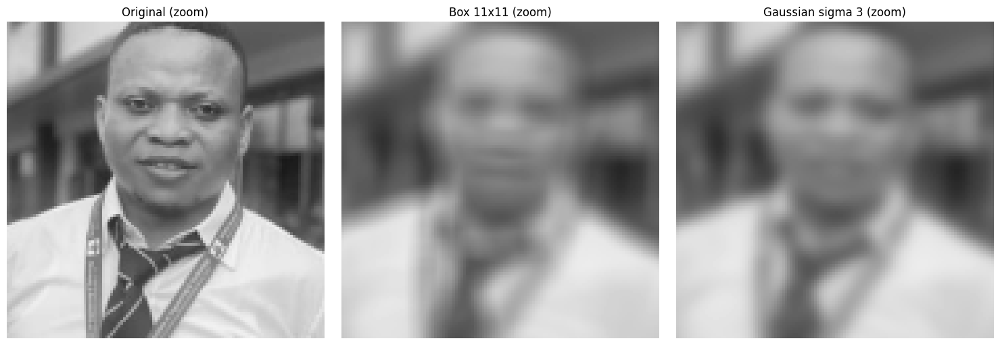

In [ ]:
# Box vs Gaussian at a similar blur: zoom in to compare.
# The box filter leaves blocky "ringing" artefacts; the Gaussian falls off smoothly.
r0, c0 = img.shape[0] // 3, img.shape[1] // 3
zoom = lambda im: im[r0:r0 + 120, c0:c0 + 120]
show([zoom(img), zoom(correlate(img, box_kernel(11), 'reflect')), zoom(correlate(img, gaussian_kernel(19, 3), 'reflect'))],
     ['Original (zoom)', 'Box 11x11 (zoom)', 'Gaussian sigma 3 (zoom)'], size=5)

## 9. Smoothing for noise removal — and the median filter

**Question: Why smooth an image at all?**

**Answer:** To reduce **noise**. Random noise changes neighbouring pixels independently, so averaging $k$ noisy pixels reduces the noise standard deviation by about a factor of $\sqrt{k}$ (for independent noise). The price is blurred edges.

**The median filter is NOT a kernel.** It replaces each pixel by the **median** of its neighbourhood:

$$
g(x, y) = \operatorname{median}\{\, f(x+s, y+t) : -a \le s \le a,\; -b \le t \le b \,\}
$$

There are no weights and no sum of products, so it is **non-linear** and cannot be written as a correlation or convolution. We include it as a contrast, because it removes **salt-and-pepper** noise far better than any averaging kernel.

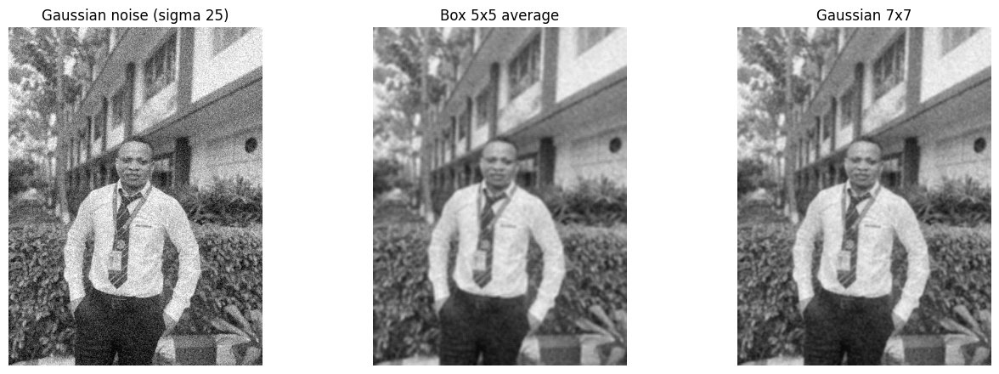

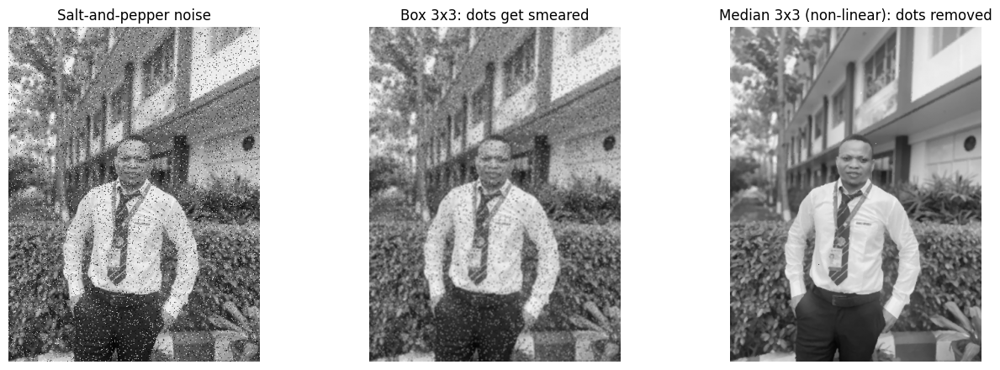

In [ ]:
rng = np.random.default_rng(1)
noisy_gauss = np.clip(img + rng.normal(0, 25, img.shape), 0, 255)

noisy_sp = img.copy()
u = rng.random(img.shape)
noisy_sp[u < 0.04] = 0          # pepper
noisy_sp[u > 0.96] = 255        # salt

show([noisy_gauss, correlate(noisy_gauss, box_kernel(5), 'reflect'), correlate(noisy_gauss, gaussian_kernel(7, 1.2), 'reflect')],
     ['Gaussian noise (sigma 25)', 'Box 5x5 average', 'Gaussian 7x7'], size=4.5)
show([noisy_sp, correlate(noisy_sp, box_kernel(3), 'reflect'), ndimage.median_filter(noisy_sp, size=3)],
     ['Salt-and-pepper noise', 'Box 3x3: dots get smeared', 'Median 3x3 (non-linear): dots removed'], size=4.5)

## 10. Sharpening kernels (high-pass filters)

**Question: How can a kernel sharpen an image?**

**Answer:** Smoothing is like **integration** (averaging). Sharpening is like **differentiation**: derivatives are large where intensity changes quickly (edges, fine detail) and zero in flat regions. We compute a derivative with a kernel and **add it back** to the image to make edges crisper.

### 10.1 The Laplacian (second derivative)

$$
\nabla^2 f = \frac{\partial^2 f}{\partial x^2} + \frac{\partial^2 f}{\partial y^2}
$$

Using the discrete second difference $\frac{\partial^2 f}{\partial x^2} \approx f(x+1,y) + f(x-1,y) - 2f(x,y)$ (and the same in $y$):

$$
\nabla^2 f(x,y) = f(x+1,y) + f(x-1,y) + f(x,y+1) + f(x,y-1) - 4f(x,y)
$$

Reading off the coefficients gives the Laplacian kernel. Including the diagonals gives the 8-neighbour version:

$$
w_{\text{4-nbr}} = \begin{bmatrix}0&1&0\\1&-4&1\\0&1&0\end{bmatrix},
\qquad
w_{\text{8-nbr}} = \begin{bmatrix}1&1&1\\1&-8&1\\1&1&1\end{bmatrix}
$$

Note the weights **sum to 0**: a flat region gives output $0$.

### 10.2 Sharpening with the Laplacian

$$
g(x,y) = f(x,y) + c\,\nabla^2 f(x,y), \qquad c = -1 \text{ (because the centre weight is negative)}
$$

Because both steps are linear, they combine into **one** kernel:

$$
w_{\text{sharpen}} = \begin{bmatrix}0&0&0\\0&1&0\\0&0&0\end{bmatrix} - \begin{bmatrix}0&1&0\\1&-4&1\\0&1&0\end{bmatrix}
= \begin{bmatrix}0&-1&0\\-1&5&-1\\0&-1&0\end{bmatrix}
\qquad(\text{weights sum to } 1)
$$

### 10.3 Unsharp masking and high-boost filtering

1. Blur the image: $\bar{f} = \text{smooth}(f)$.
2. Subtract to get the **mask** (the detail that blurring removed): $g_{\text{mask}} = f - \bar{f}$.
3. Add the mask back with weight $k$: $g = f + k\, g_{\text{mask}}$.

$k = 1$ is **unsharp masking**; $k > 1$ is **high-boost filtering**.

Laplacian (4-nbr), sum = 0.0 
 [[ 0.  1.  0.]
 [ 1. -4.  1.]
 [ 0.  1.  0.]]

Sharpen = identity - Laplacian, sum = 1.0 
 [[ 0. -1.  0.]
 [-1.  5. -1.]
 [ 0. -1.  0.]]


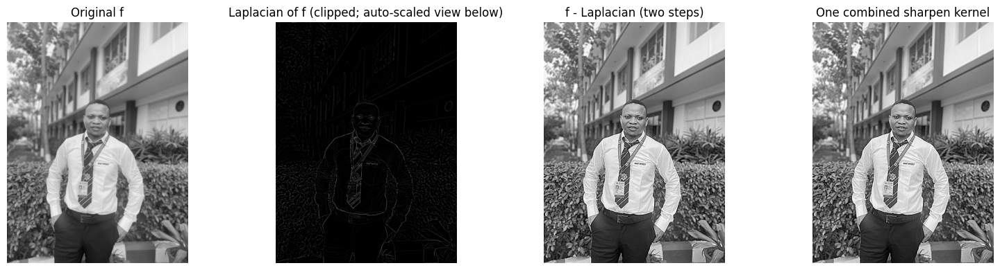

Two-step result == single combined kernel? True


In [ ]:
identity = np.zeros((3, 3)); identity[1, 1] = 1
lap4 = np.array([[0, 1, 0], [1, -4, 1], [0, 1, 0]], float)
lap8 = np.array([[1, 1, 1], [1, -8, 1], [1, 1, 1]], float)
sharpen4 = identity - lap4
sharpen8 = identity - lap8

print('Laplacian (4-nbr), sum =', lap4.sum(), '\n', lap4)
print('\nSharpen = identity - Laplacian, sum =', sharpen4.sum(), '\n', sharpen4)

L = correlate(img, lap4, 'reflect')
show([img, L, np.clip(img - L, 0, 255), np.clip(correlate(img, sharpen4, 'reflect'), 0, 255)],
     ['Original f', 'Laplacian of f (clipped; auto-scaled view below)', 'f - Laplacian (two steps)', 'One combined sharpen kernel'],
     cols=4, scale=None)
print('Two-step result == single combined kernel?', np.allclose(img - L, correlate(img, sharpen4, 'reflect')))

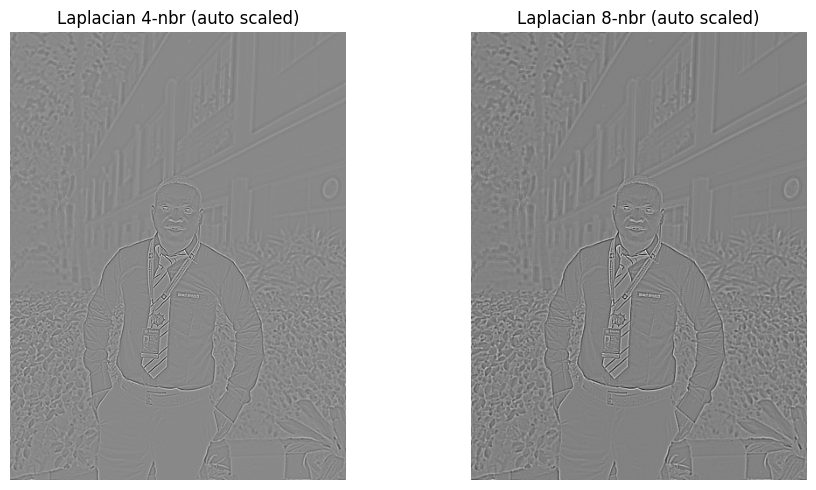

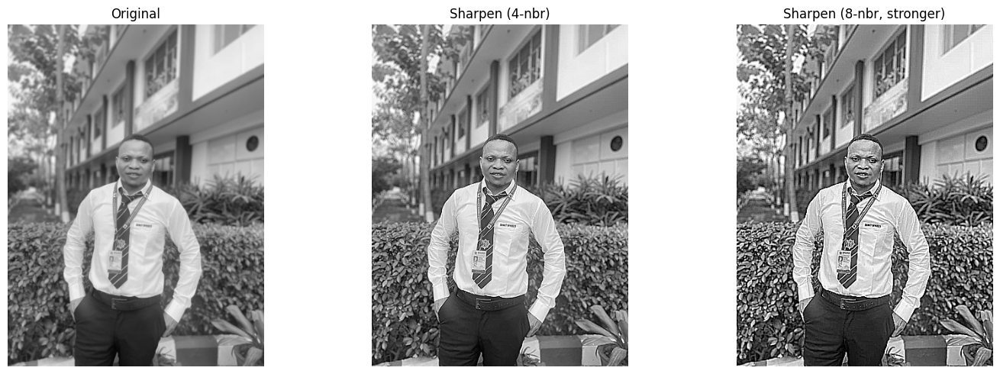

In [ ]:
# Show the Laplacian with its own min..max scaling, and the 8-neighbour version
show([L, correlate(img, lap8, 'reflect')], ['Laplacian 4-nbr (auto scaled)', 'Laplacian 8-nbr (auto scaled)'], scale='auto', size=5)
show([img, np.clip(correlate(img, sharpen4, 'reflect'), 0, 255), np.clip(correlate(img, sharpen8, 'reflect'), 0, 255)],
     ['Original', 'Sharpen (4-nbr)', 'Sharpen (8-nbr, stronger)'], size=5)

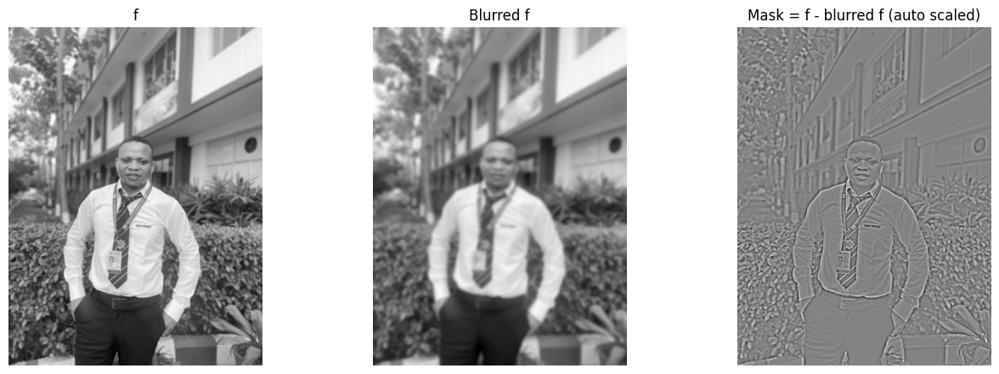

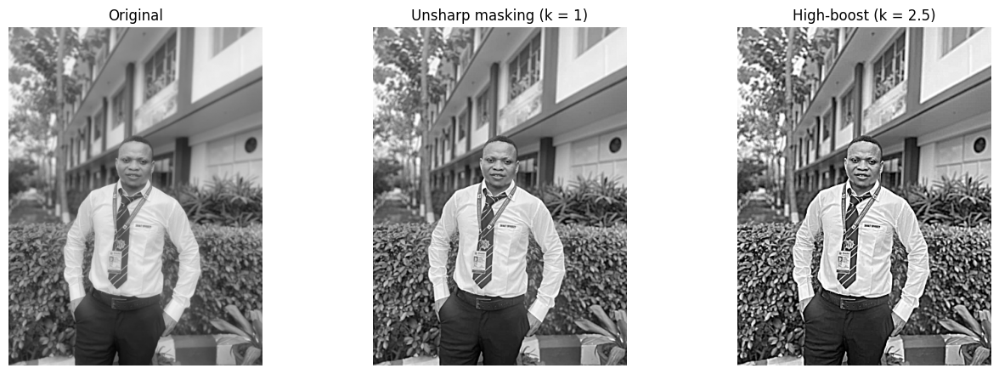

In [ ]:
# Unsharp masking and high-boost filtering
blur = correlate(img, gaussian_kernel(9, 2), 'reflect')
mask = img - blur
show([img, blur, mask], ['f', 'Blurred f', 'Mask = f - blurred f (auto scaled)'], scale='auto', size=4.5)
show([img, np.clip(img + 1 * mask, 0, 255), np.clip(img + 2.5 * mask, 0, 255)],
     ['Original', 'Unsharp masking (k = 1)', 'High-boost (k = 2.5)'], size=4.5)

## 11. First-derivative kernels: Prewitt and Sobel (edge detection)

**Question: How do we find edges with a kernel?**

**Answer:** Edges are where the **first derivative** (the gradient) is large. The gradient is a vector:

$$
\nabla f = \begin{bmatrix} g_x \\ g_y \end{bmatrix} = \begin{bmatrix} \partial f / \partial x \\ \partial f / \partial y \end{bmatrix},
\qquad
M(x,y) = \sqrt{g_x^2 + g_y^2} \;\approx\; |g_x| + |g_y|
$$

$M(x,y)$ is the **gradient magnitude** (edge strength). Each partial derivative is a difference across the centre, averaged over three rows or columns to resist noise. Remember $x$ is the row, so $g_x$ responds to **horizontal** edges.

$$
\text{Prewitt: }\;
w_x = \begin{bmatrix}-1&-1&-1\\0&0&0\\1&1&1\end{bmatrix},\quad
w_y = \begin{bmatrix}-1&0&1\\-1&0&1\\-1&0&1\end{bmatrix}
$$

$$
\text{Sobel: }\;
w_x = \begin{bmatrix}-1&-2&-1\\0&0&0\\1&2&1\end{bmatrix},\quad
w_y = \begin{bmatrix}-1&0&1\\-2&0&2\\-1&0&1\end{bmatrix}
$$

Sobel gives the centre row or column weight $2$, which adds a little smoothing. Both kernels **sum to 0** and are **anti-symmetric**, so convolution only flips the sign of $g_x$ and $g_y$ — the magnitude $M$ is the same either way.

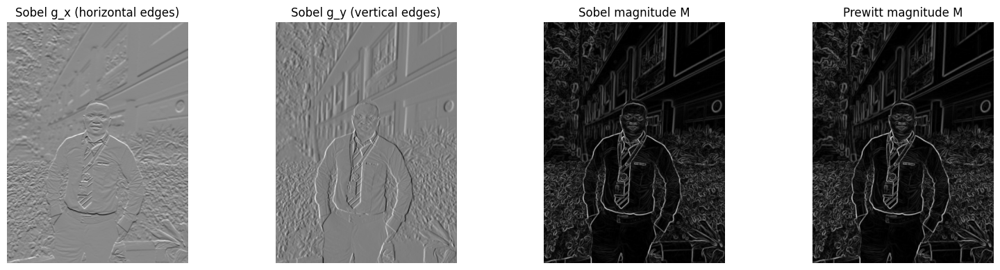

Magnitude identical for correlation and convolution? True


In [ ]:
prewitt_x = np.array([[-1, -1, -1], [0, 0, 0], [1, 1, 1]], float)
prewitt_y = prewitt_x.T
sobel_x = np.array([[-1, -2, -1], [0, 0, 0], [1, 2, 1]], float)
sobel_y = sobel_x.T

gx, gy = correlate(img, sobel_x, 'reflect'), correlate(img, sobel_y, 'reflect')
Msobel = np.sqrt(gx**2 + gy**2)
px, py = correlate(img, prewitt_x, 'reflect'), correlate(img, prewitt_y, 'reflect')
Mprewitt = np.sqrt(px**2 + py**2)

show([gx, gy, Msobel, Mprewitt],
     ['Sobel g_x (horizontal edges)', 'Sobel g_y (vertical edges)', 'Sobel magnitude M', 'Prewitt magnitude M'],
     cols=4, scale='auto')

gxc, gyc = convolve(img, sobel_x, 'reflect'), convolve(img, sobel_y, 'reflect')
print('Magnitude identical for correlation and convolution?', np.allclose(Msobel, np.sqrt(gxc**2 + gyc**2)))

## 12. Properties of kernels

### 12.1 What the sum of the weights tells you

**Question: Can I predict a kernel's effect without running it?**

**Answer:** Look at the sum of its weights. On a flat region where every pixel equals $c$:

$$
g(x,y) = \sum_s \sum_t w(s,t)\, c = c \sum_s \sum_t w(s,t)
$$

| Sum of weights | Effect on flat regions | Typical kernels |
|---|---|---|
| $= 1$ | brightness preserved | box, Gaussian, sharpen |
| $= 0$ | flat regions become 0, only changes survive | Laplacian, Sobel, Prewitt |
| $> 1$ or $< 1$ | image gets brighter or darker | un-normalised kernels |

### 12.2 Convolution is commutative and associative; correlation is not

$$
w * f = f * w, \qquad (w_1 * w_2) * f = w_1 * (w_2 * f)
$$

Associativity means two filters applied one after another can be **pre-combined into one kernel** $w_1 * w_2$.

### 12.3 Separable kernels

A kernel is **separable** if it is an outer product of a column vector and a row vector, $w = \mathbf{v}\,\mathbf{h}^{\mathsf T}$. Then a 2-D filtering can be done as a 1-D pass down the columns followed by a 1-D pass along the rows. For an $m \times m$ kernel this cuts the work per pixel from $m^2$ to $2m$ multiplications. Box and Gaussian kernels are separable; so is Sobel:

$$
\frac{1}{9}\begin{bmatrix}1&1&1\\1&1&1\\1&1&1\end{bmatrix} = \frac{1}{3}\begin{bmatrix}1\\1\\1\end{bmatrix}\cdot\frac{1}{3}\begin{bmatrix}1&1&1\end{bmatrix},
\qquad
\begin{bmatrix}-1&-2&-1\\0&0&0\\1&2&1\end{bmatrix} = \begin{bmatrix}-1\\0\\1\end{bmatrix}\begin{bmatrix}1&2&1\end{bmatrix}
$$

In [ ]:
flat = np.full((6, 6), 100.0)
for name, k in [('Box 3x3', box_kernel(3)), ('Gaussian', gaussian_kernel(5, 1)), ('Sharpen', sharpen4),
                ('Laplacian', lap4), ('Sobel x', sobel_x), ('All ones (sum 9)', np.ones((3, 3)))]:
    centre_value = correlate(flat, k)[3, 3]
    print(f'{name:18s} sum of weights = {k.sum():5.2f}  ->  flat region of 100 becomes {centre_value:7.2f}')

Box 3x3            sum of weights =  1.00  ->  flat region of 100 becomes  100.00
Gaussian           sum of weights =  1.00  ->  flat region of 100 becomes  100.00
Sharpen            sum of weights =  1.00  ->  flat region of 100 becomes  100.00
Laplacian          sum of weights =  0.00  ->  flat region of 100 becomes    0.00
Sobel x            sum of weights =  0.00  ->  flat region of 100 becomes    0.00
All ones (sum 9)   sum of weights =  9.00  ->  flat region of 100 becomes  900.00


In [ ]:
# Associativity: blurring then taking the Laplacian == one combined kernel (Laplacian of Gaussian)
g1 = gaussian_kernel(7, 1.2)
combined = signal.convolve2d(g1, lap4)                   # full convolution: 9x9 kernel
two_steps = signal.convolve2d(signal.convolve2d(img, g1, mode='full'), lap4, mode='full')
one_step = signal.convolve2d(img, combined, mode='full')
print('Two kernels one after another == one combined kernel?', np.allclose(two_steps, one_step))
print('Commutative: w*f == f*w ?', np.allclose(signal.convolve2d(F, w_example), signal.convolve2d(w_example, F)))
print('Correlation is NOT commutative:', not np.allclose(signal.correlate2d(F, w_example), signal.correlate2d(w_example, F)))

# Separability: column pass then row pass equals the full 2-D Sobel
v, h = np.array([[-1], [0], [1]], float), np.array([[1, 2, 1]], float)
print('\nSobel == v @ h ?', np.allclose(v @ h, sobel_x))
print('Separable filtering == full 2-D filtering?', np.allclose(correlate(correlate(img, v, 'reflect'), h, 'reflect'), correlate(img, sobel_x, 'reflect')))

Two kernels one after another == one combined kernel? True
Commutative: w*f == f*w ? True
Correlation is NOT commutative: True

Sobel == v @ h ? True
Separable filtering == full 2-D filtering? True


## 13. Gallery: every kernel on your image

All the kernels from this notebook side by side, applied to your uploaded image. Results that can be negative (edges, Laplacian) are shown as absolute values so that edges appear bright.

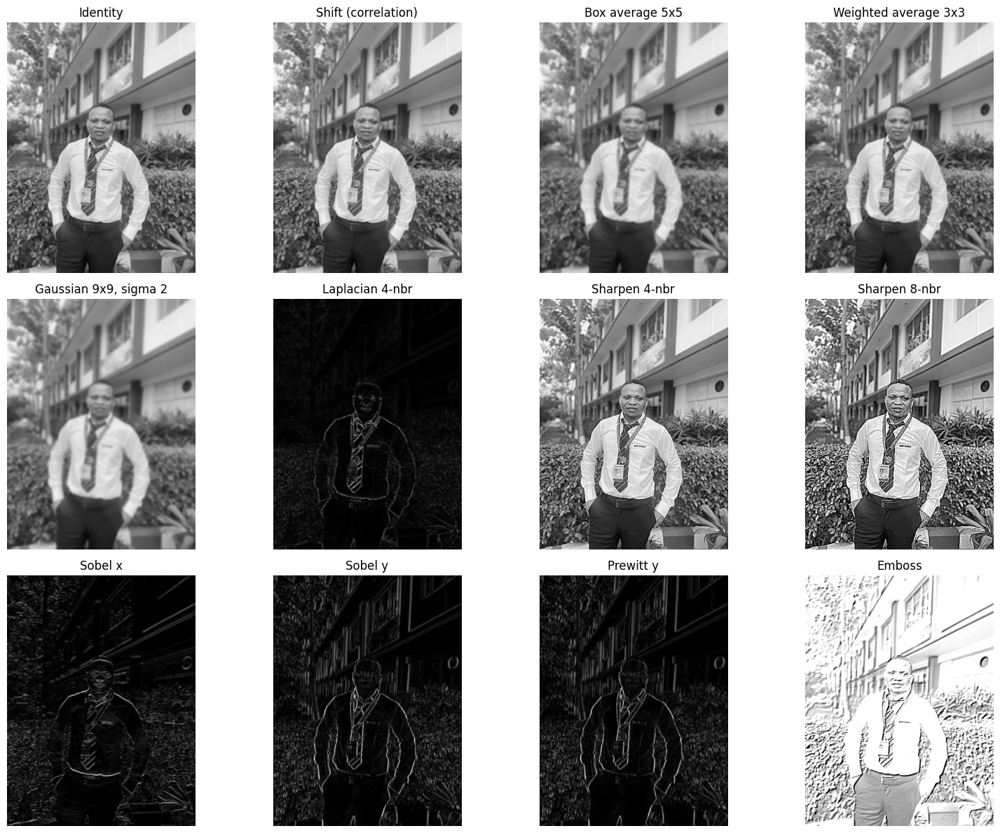

In [ ]:
emboss = np.array([[-2, -1, 0], [-1, 1, 1], [0, 1, 2]], float)
shift_right = np.array([[0, 0, 0], [1, 0, 0], [0, 0, 0]], float)

KERNELS = {
    'Identity':               identity,
    'Shift (correlation)':    shift_right,
    'Box average 5x5':        box_kernel(5),
    'Weighted average 3x3':   weighted_avg_kernel(),
    'Gaussian 9x9, sigma 2':  gaussian_kernel(9, 2),
    'Laplacian 4-nbr':        lap4,
    'Sharpen 4-nbr':          sharpen4,
    'Sharpen 8-nbr':          sharpen8,
    'Sobel x':                sobel_x,
    'Sobel y':                sobel_y,
    'Prewitt y':              prewitt_y,
    'Emboss':                 emboss,
}
edge_like = {'Laplacian 4-nbr', 'Sobel x', 'Sobel y', 'Prewitt y'}

results, titles = [], []
for name, k in KERNELS.items():
    out = correlate(img, k, 'reflect')
    if name in edge_like:
        out = np.abs(out); out = out / out.max() * 255
    elif name == 'Emboss':
        out = out + 128
    results.append(out); titles.append(name)
show(results, titles, cols=4, size=4)

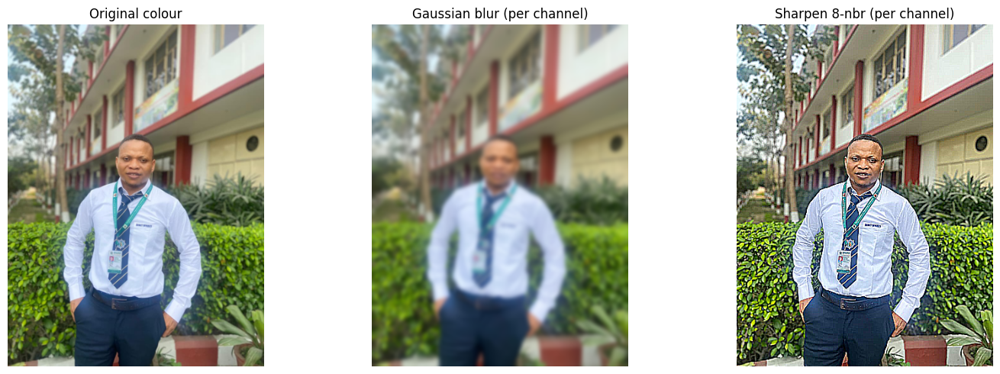

In [ ]:
# Colour images: apply the same kernel to each channel R, G, B separately
def filter_color(rgb, w, padding='reflect'):
    return np.dstack([correlate(rgb[:, :, c].astype(float), w, padding) for c in range(3)])

show([img_color, filter_color(img_color, gaussian_kernel(15, 3)), filter_color(img_color, sharpen8)],
     ['Original colour', 'Gaussian blur (per channel)', 'Sharpen 8-nbr (per channel)'], size=5)

## 14. Interactive kernel playground

Choose a kernel type, its size or sigma, and the operation. The cell shows the kernel you chose, the kernel actually laid on the image (rotated for convolution), and the result on your image.

To try **your own kernel**, edit `my_kernel` in the cell after the playground and run it.

In [ ]:
def playground(kind='Gaussian', size=7, sigma=1.5, k_boost=1.5, operation='correlation'):
    if size % 2 == 0:
        size += 1
    if kind == 'Box average':
        w = box_kernel(size)
    elif kind == 'Gaussian':
        w = gaussian_kernel(size, sigma)
    elif kind == 'Weighted average 3x3':
        w = weighted_avg_kernel()
    elif kind == 'Sharpen 4-nbr':
        w = sharpen4
    elif kind == 'Sharpen 8-nbr':
        w = sharpen8
    elif kind == 'High-boost (Gaussian based)':
        G = gaussian_kernel(size, sigma)
        delta = np.zeros_like(G); delta[size // 2, size // 2] = 1
        w = delta + k_boost * (delta - G)            # f + k (f - blur)  as ONE kernel
    elif kind == 'Sobel x':
        w = sobel_x
    elif kind == 'Laplacian 4-nbr':
        w = lap4
    else:
        w = shift_right

    used = w if operation == 'correlation' else np.rot90(w, 2)
    out = correlate(img, used, 'reflect')

    fig, ax = plt.subplots(1, 4, figsize=(19, 4.8))
    if w.shape[0] <= 7:
        show_matrix(ax[0], w, f'Kernel w (sum = {w.sum():.2f})', fmt='{:.2f}', cmap='YlOrBr')
        show_matrix(ax[1], used, 'Laid on the image' + (' (rotated 180)' if operation == 'convolution' else ''), fmt='{:.2f}', cmap='RdPu')
    else:
        ax[0].imshow(w, cmap='viridis'); ax[0].set_title(f'Kernel w {w.shape[0]}x{w.shape[1]} (sum = {w.sum():.2f})'); ax[0].axis('off')
        ax[1].imshow(used, cmap='viridis'); ax[1].set_title('Laid on the image'); ax[1].axis('off')
    ax[2].imshow(img, cmap='gray', vmin=0, vmax=255); ax[2].set_title('Input f'); ax[2].axis('off')
    if w.sum() == 0:
        ax[3].imshow(out, cmap='gray'); ax[3].set_title(f'{operation} result (auto scaled)')
    else:
        ax[3].imshow(np.clip(out, 0, 255), cmap='gray', vmin=0, vmax=255); ax[3].set_title(f'{operation} result')
    ax[3].axis('off')
    plt.tight_layout(); plt.show()

try:
    import ipywidgets as widgets
    widgets.interact(playground,
        kind=widgets.Dropdown(options=['Box average', 'Weighted average 3x3', 'Gaussian', 'Sharpen 4-nbr', 'Sharpen 8-nbr',
                                       'High-boost (Gaussian based)', 'Laplacian 4-nbr', 'Sobel x', 'Shift'], value='Gaussian'),
        size=widgets.IntSlider(min=3, max=31, step=2, value=7, description='size (odd)'),
        sigma=widgets.FloatSlider(min=0.5, max=8, step=0.5, value=1.5),
        k_boost=widgets.FloatSlider(min=0.5, max=5, step=0.5, value=1.5, description='k (boost)'),
        operation=widgets.ToggleButtons(options=['correlation', 'convolution']))
except ImportError:
    playground()

interactive(children=(Dropdown(description='kind', index=2, options=('Box average', 'Weighted average 3x3', 'G…

Sum of weights = 1.0
Symmetric under 180 rotation?    True
Anti-symmetric under 180 rotation? False


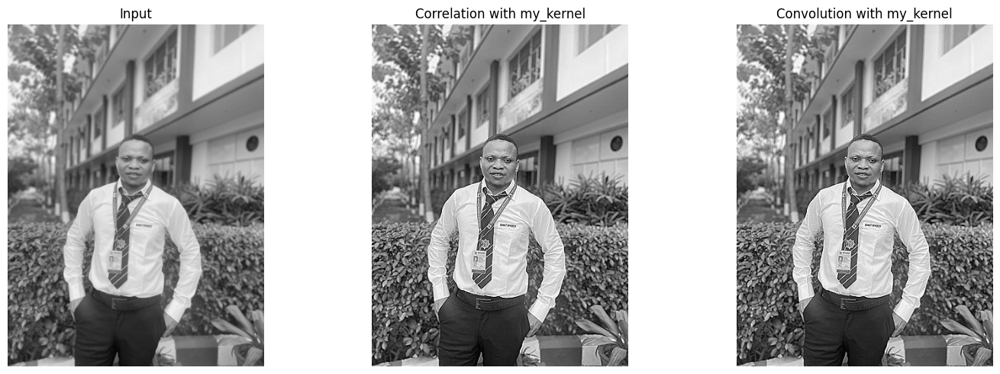

In [ ]:
# ---- Your own kernel: change the numbers and run this cell ----
my_kernel = np.array([[ 0, -1,  0],
                      [-1,  5, -1],
                      [ 0, -1,  0]], dtype=float)

print('Sum of weights =', my_kernel.sum())
print('Symmetric under 180 rotation?   ', np.allclose(my_kernel, np.rot90(my_kernel, 2)))
print('Anti-symmetric under 180 rotation?', np.allclose(my_kernel, -np.rot90(my_kernel, 2)))
c_out, v_out = correlate(img, my_kernel, 'reflect'), convolve(img, my_kernel, 'reflect')
scale = 'auto' if abs(my_kernel.sum()) < 1e-9 else None
show([img, c_out, v_out], ['Input', 'Correlation with my_kernel', 'Convolution with my_kernel'], size=5, scale=scale)

## 15. Summary

| Concept | Formula | Key idea |
|---|---|---|
| Kernel | $w(s,t),\; s \in [-a,a],\; t \in [-b,b]$ | small weight matrix, indexed from its centre |
| Correlation | $g(x,y) = \sum_s\sum_t w(s,t)\, f(x+s, y+t)$ | slide the kernel as written |
| Convolution | $g(x,y) = \sum_s\sum_t w(s,t)\, f(x-s, y-t)$ | rotate the kernel 180°, then correlate |
| Equal when | $w(-s,-t) = w(s,t)$ | symmetric kernels (box, Gaussian, Laplacian) |
| Output size | valid: $(M-m+1)\times(N-n+1)$; padded: $M\times N$ | padding with $a = \tfrac{m-1}{2}$ |
| Box average | $w = \tfrac{1}{m^2}\mathbf{1}$ | arithmetic mean of the neighbourhood |
| Gaussian | $G(s,t) = K e^{-(s^2+t^2)/2\sigma^2}$ | nearer pixels count more; $\sigma$ sets the blur |
| Laplacian | $\nabla^2 f = f(x\pm1,y) + f(x,y\pm1) - 4f(x,y)$ | second derivative; weights sum to 0 |
| Sharpening | $g = f - \nabla^2 f$ | kernel $\begin{bmatrix}0&-1&0\\-1&5&-1\\0&-1&0\end{bmatrix}$ |
| Unsharp / high-boost | $g = f + k\,(f - \bar f)$ | $k = 1$ unsharp, $k > 1$ high-boost |
| Gradient | $M = \sqrt{g_x^2 + g_y^2}$ | Sobel / Prewitt find edges |
| Median | $\operatorname{median}$ of neighbourhood | non-linear, not a kernel; best for salt-and-pepper |

## Exercises for students

1. By hand, compute $g(1,1)$ for the $5 \times 5$ image in Section 3 using both correlation and convolution with the numbered kernel. Check your answers with `correlate_formula` and `convolve_formula`.
2. Prove that for the box kernel, correlation and convolution give the same result. Which property of the kernel did you use?
3. A $7 \times 7$ kernel is applied to a $256 \times 256$ image without padding. What is the output size? How many padding rows and columns are needed to keep the size $256 \times 256$?
4. Derive the 8-neighbour Laplacian sharpening kernel $\begin{bmatrix}-1&-1&-1\\-1&9&-1\\-1&-1&-1\end{bmatrix}$ from $g = f - \nabla^2 f$.
5. Using the Gaussian formula, compute the $3 \times 3$ Gaussian kernel for $\sigma = 1$ by hand (before normalising), then normalise it. Compare with `gaussian_kernel(3, 1)`.
6. Write the high-boost filter $g = f + k(f - \bar f)$ with a $3 \times 3$ box blur as a **single** $3 \times 3$ kernel for $k = 2$.
7. Upload a noisy photo. Which works better on it, the Gaussian or the median filter? Explain using the type of noise.